# تحلیل داده‌های نمرات دانش‌آموزان

### کتابخانه ها  

In [129]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from scipy.stats import ttest_ind
from scipy.stats import pearsonr

### خواندن فایل

In [84]:
df = pd.read_csv("exams.csv")

### نمایش چند مورد اول

In [85]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,male,group A,high school,standard,completed,67,67,63
1,female,group D,some high school,free/reduced,none,40,59,55
2,male,group E,some college,free/reduced,none,59,60,50
3,male,group B,high school,standard,none,77,78,68
4,male,group E,associate's degree,standard,completed,78,73,68


### نمایش چند مورد اخر

In [86]:
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,male,group C,high school,standard,none,73,70,65
996,male,group D,associate's degree,free/reduced,completed,85,91,92
997,female,group C,some high school,free/reduced,none,32,35,41
998,female,group C,some college,standard,none,73,74,82
999,male,group A,some college,standard,completed,65,60,62


دیتاست شامل متغیرهای دسته ای مانند جنسیت، گروه نژادی، سطح تحصیلات والدین، نوع ناهار و وضعیت دوره آمادگی آزمون و همچنین متغیرهای عددی شامل نمرات ریاضی، خواندن و نوشتن است

### برسی اطلاعات کلی   

In [87]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


دیتاست شامل 1000 رکورد و 8 ستون است. هیچ مقدار گمشده‌ای ندارد و از 5 ستون متنی و 3 ستون عددی تشکیل شده است

### آمار توصیفی

In [88]:
df.describe()

,math score,reading score,writing score
count,1000.000000,1000.000000,1000.000000
mean,66.396000,69.002000,67.738000
std,15.402871,14.737272,15.600985
min,13.000000,27.000000,23.000000
25%,56.000000,60.000000,58.000000
50%,66.500000,70.000000,68.000000
75%,77.000000,79.000000,79.000000
max,100.000000,100.000000,100.000000


### دسته بندی 

In [93]:
numerical_cols = ['math score', 'reading score', 'writing score']   # متغیرهای عددی
nominal_cols = ['race/ethnicity']                                    # متغیرهای اسمی
binary_cols = ['gender', 'lunch', 'test preparation course']         # متغیرهای دودویی 
ordinal_cols = ['parental level of education']                       # متغیر ترتیبی 

### انحراف معیار

In [89]:
for col in numerical_cols:
    print(f"{col}: {df[col].std():.2f}")

math score: 15.40
reading score: 14.74
writing score: 15.60


### محاسبه واریانس

In [91]:
for col in numerical_cols:
    print(f"{col}: {df[col].var():.2f}")

math score: 237.25
reading score: 217.19
writing score: 243.39


### کدام درس بیشترین پراکندگی را دارد ؟

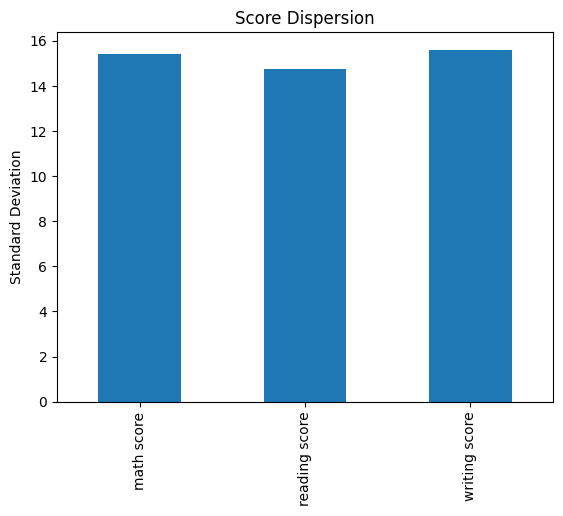

In [90]:
std = df[numerical_cols].std()

std.plot(kind='bar')
plt.ylabel("Standard Deviation")
plt.title("Score Dispersion")
plt.show()

پراکندگی نمرات در هر سه درس نزدیک به هم است. بیشترین پراکندگی مربوط به **نوشتن** و کمترین آن مربوط به **خواندن** است

### تعداد مقادیر یکتا

In [92]:
df.nunique().sort_values()

gender                          2
lunch                           2
test preparation course         2
race/ethnicity                  5
parental level of education     6
reading score                  73
writing score                  76
math score                     77
dtype: int64

واریانس نمرات در هر سه درس نزدیک به هم است. بیشترین واریانس مربوط به **نوشتن** و کمترین آن مربوط به **خواندن** است

در این بخش، ستون‌های دیتاست بر اساس نوع داده به چهار گروه شامل متغیرهای عددی، اسمی، دودویی و ترتیبی تقسیم شدند تا در مراحل بعدی تحلیل، از روش مناسب برای هر گروه استفاده شود

### بررسی نوع داده‌ها  

In [94]:
df.dtypes

gender                           str
race/ethnicity                   str
parental level of education      str
lunch                            str
test preparation course          str
math score                     int64
reading score                  int64
writing score                  int64
dtype: object

### بررسی مقادیر گمشده

In [95]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

مقادیر گمشده نداریم 

## بررسی داده‌های تکراری

In [133]:
print(df.duplicated().sum())
df = df.drop_duplicates()
print(df.shape)

0
(999, 8)


### بررسی داده‌های پرت

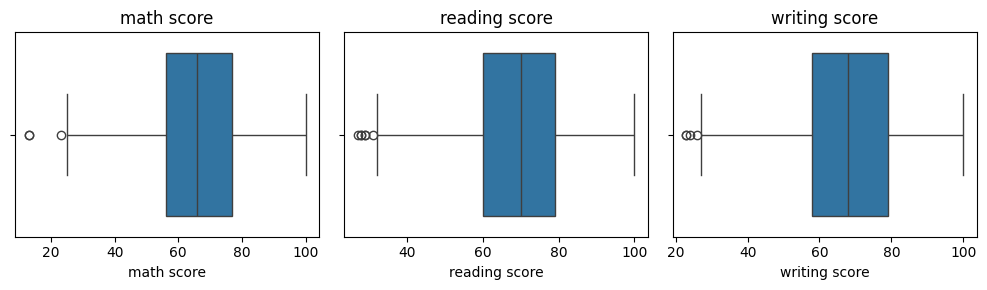

In [98]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for i, col in enumerate(numerical_cols):
    sns.boxplot(data=df, x=col, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout()
plt.show()

نمودار جعبه‌ای برای بررسی توزیع نمرات و شناسایی داده‌های پرت رسم شد. با بررسی نموداردرهرسه درس تعدادی داده پرت وجود دارد و پراکندگی نمرات در سه درس تقریباً یکی است

### IQR شناسایی داده‌های پرت با

In [99]:
def outliers(df, col):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    return df[(df[col] < low) | (df[col] > high)]

In [100]:
for col in numerical_cols:
    print(col, ":", len(outliers(df, col)), "outliers")

math score : 3 outliers
reading score : 6 outliers
writing score : 4 outliers


<div dir="rtl" align="right">

در این تابع با روش IQR دادههای پرت شناسایی و در هر ستون داده پرت وجود دارد و بیشترن داده پرت برای درس خواندن است و  ولی به خاطر واقعی بودن نمرات دانش اموزان حذف نمیشود  و تمامی داده ها  برای تحلیل حفظ میشوند

</div>

### تحلیل توزیع داده‌ها

### رسم Histogram و KDE

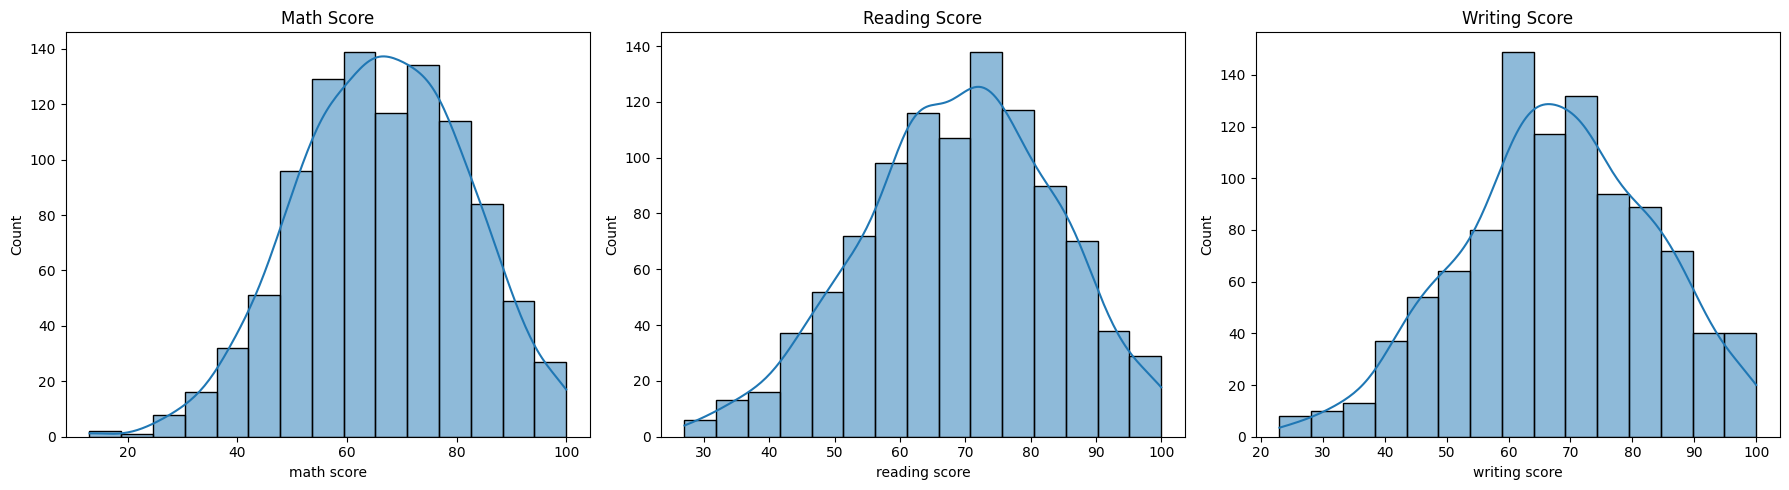

In [111]:
plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.histplot(df['math score'], bins=15, kde=True)
plt.title("Math Score")

plt.subplot(1, 3, 2)
sns.histplot(df['reading score'], bins=15, kde=True)
plt.title("Reading Score")

plt.subplot(1, 3, 3)
sns.histplot(df['writing score'], bins=15, kde=True)
plt.title("Writing Score")

plt.tight_layout()
plt.show()

نمودارها نشان می‌دهند که بیشتر نمرات در بازه **60 تا 80** قرار دارند و توزیع نمرات هر سه درس تقریباً متقارن است. همچنین، تعداد نمرات خیلی پایین و خیلی بالا نسبت به نمرات میانی کمتر است

### بررسی توزیع متغیرهای دسته‌ای

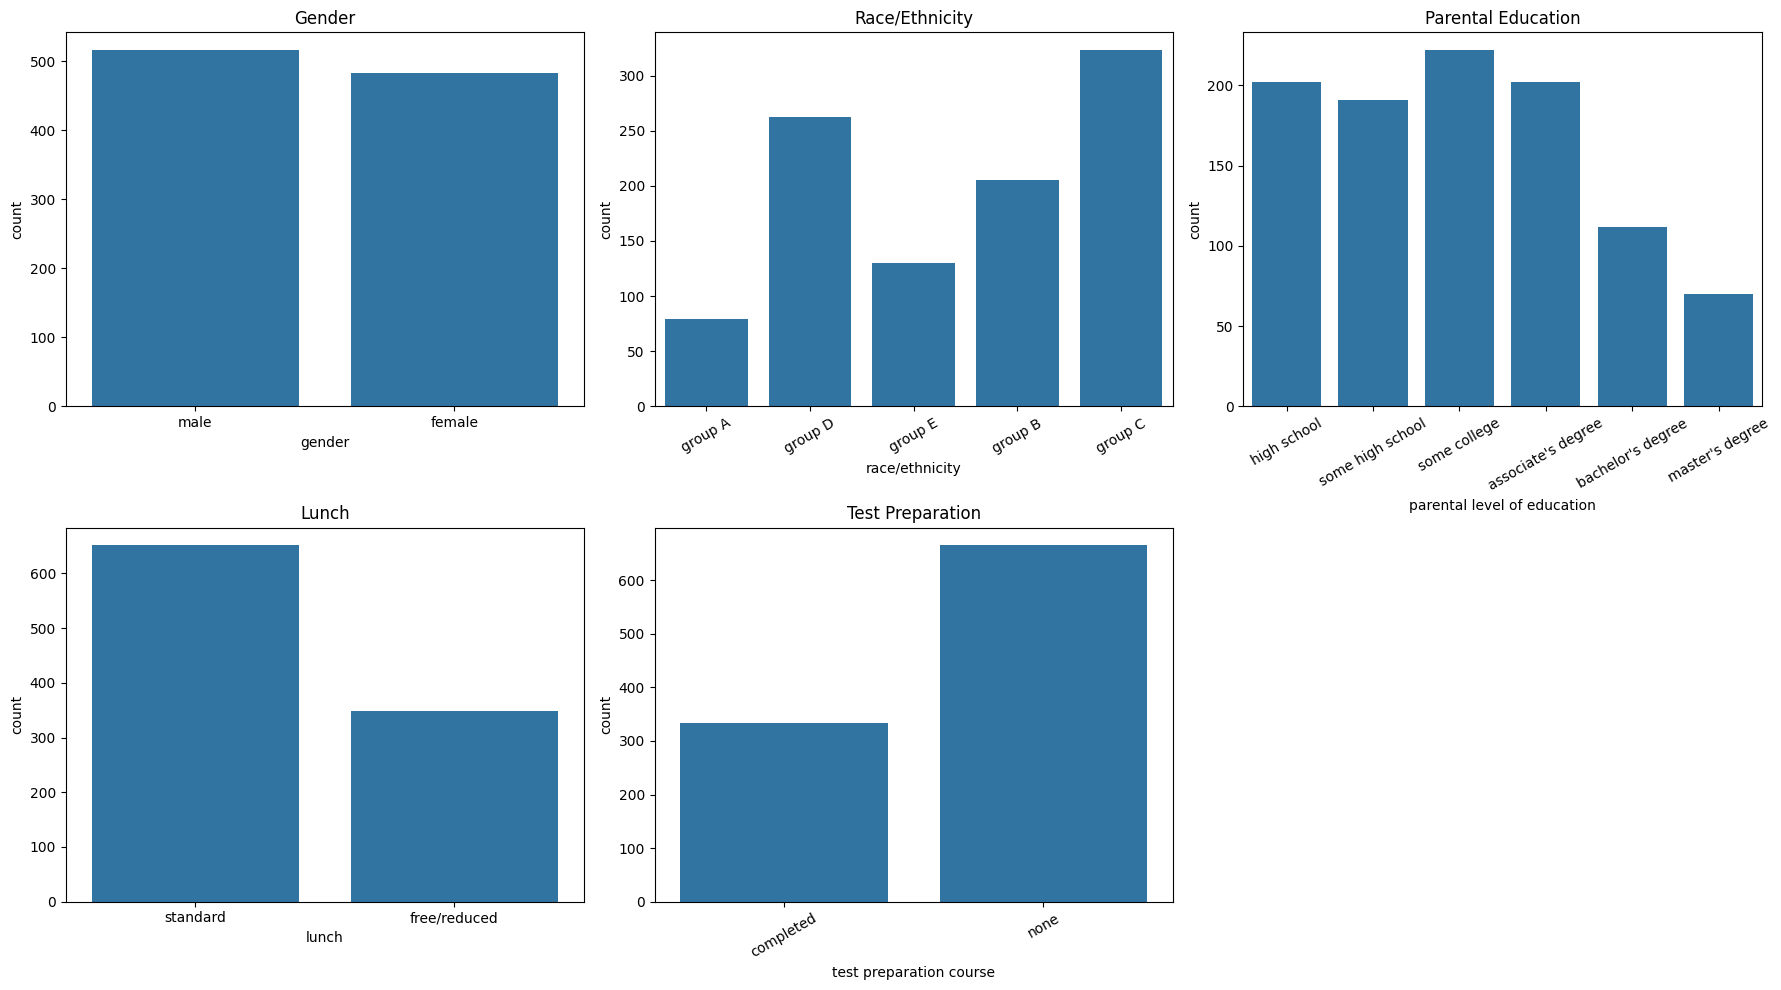

In [113]:

plt.figure(figsize=(18, 10))

plt.subplot(2, 3, 1)
sns.countplot(x=df['gender'])
plt.title("Gender")

plt.subplot(2, 3, 2)
sns.countplot(x=df['race/ethnicity'])
plt.title("Race/Ethnicity")
plt.xticks(rotation=30)

plt.subplot(2, 3, 3)
sns.countplot(x=df['parental level of education'])
plt.title("Parental Education")
plt.xticks(rotation=30)

plt.subplot(2, 3, 4)
sns.countplot(x=df['lunch'])
plt.title("Lunch")

plt.subplot(2, 3, 5)
sns.countplot(x=df['test preparation course'])
plt.title("Test Preparation")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

<div style="direction: rtl; text-align: right;">
بررسی نمودارهای متغیرهای دسته‌ای نشان می‌دهد که تعداد دانش‌آموزان دختر و پسر تقریباً برابر است. گروه C بیشترین فراوانی را در بین گروه‌های نژادی دارد. بیشتر والدین دارای سطح تحصیلات **Some College** هستند. همچنین، بیشتر دانش‌آموزان از ناهار استاندارد استفاده می‌کنند و در دوره آمادگی آزمون شرکت نکرده‌اند.
</div>

## آیا جنسیت روی نمرات تأثیر دارد؟

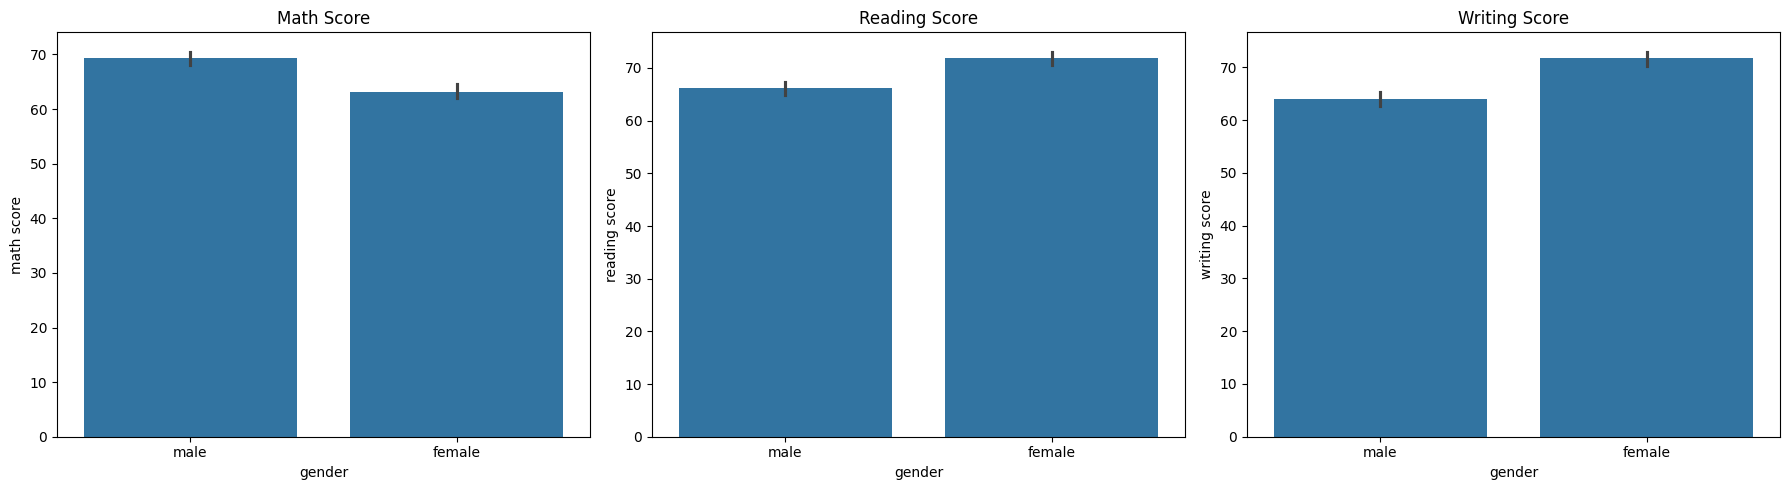

In [116]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(18, 5))

plt.subplot(1, 3, 1)
sns.barplot(data=df, x='gender', y='math score')
plt.title("Math Score")

plt.subplot(1, 3, 2)
sns.barplot(data=df, x='gender', y='reading score')
plt.title("Reading Score")

plt.subplot(1, 3, 3)
sns.barplot(data=df, x='gender', y='writing score')
plt.title("Writing Score")

plt.tight_layout()
plt.show()

<div style="direction: rtl; text-align: right;">
نمودارهای میله‌ای میانگین نمرات دختران و پسران را در سه درس نشان می‌دهند. نتایج نشان می‌دهد که پسران در درس ریاضی میانگین نمره بالاتری نسبت به دختران دارند، در حالی که دختران در درس‌های خواندن و نوشتن میانگین نمرات بالاتری کسب کرده‌اند
</div>

## آیا دوره آمادگی باعث افزایش نمرات شده است؟

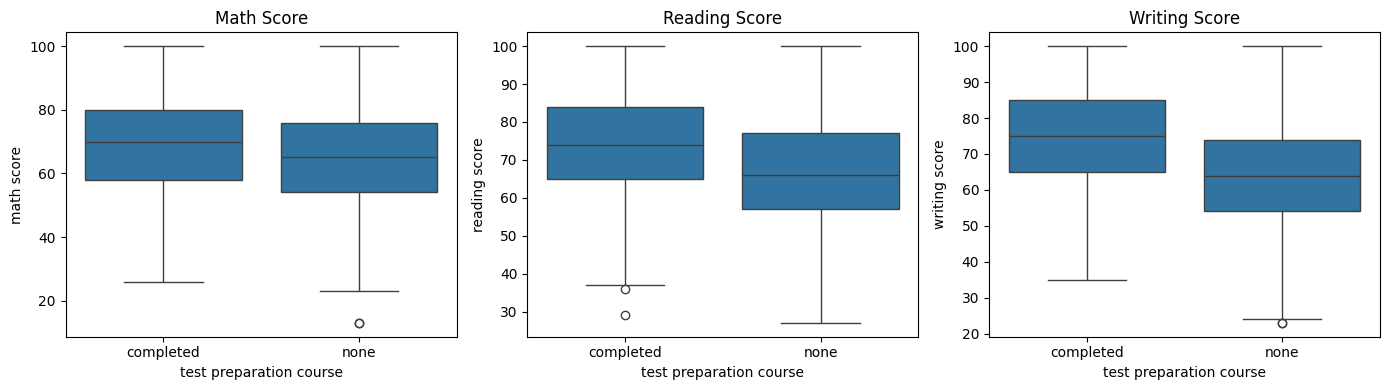

In [118]:
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
sns.boxplot(x='test preparation course', y='math score', data=df)
plt.title("Math Score")

plt.subplot(1, 3, 2)
sns.boxplot(x='test preparation course', y='reading score', data=df)
plt.title("Reading Score")

plt.subplot(1, 3, 3)
sns.boxplot(x='test preparation course', y='writing score', data=df)
plt.title("Writing Score")

plt.tight_layout()
plt.show()

دانش‌آموزانی که دوره آمادگی آزمون را گذرانده‌اند، در هر سه درس ریاضی، خواندن و نوشتن عملکرد بهتری داشته‌اند. بنابراین می‌توان گفت بین شرکت در دوره آمادگی آزمون و افزایش نمرات دانش‌آموزان ارتباط مثبت وجود دارد.

### T-Test

In [136]:
completed = df[df['test preparation course']=='completed']['math score']
none = df[df['test preparation course']=='none']['math score']

t_stat, p_value = ttest_ind(completed, none)

print("t:",t_stat)
print("p:",p_value)

t: 4.762070606334978
p: 2.1999104253284263e-06


یعنی بین میانگین نمره ریاضی دانش‌آموزانی که دوره آمادگی آزمون را گذرانده‌اند و کسانی که نگذرانده‌اند، تفاوت معنادار آماری وجود دارد.

### ایا سطح تحصیلات والدین روی نمره تاثیر دارد؟

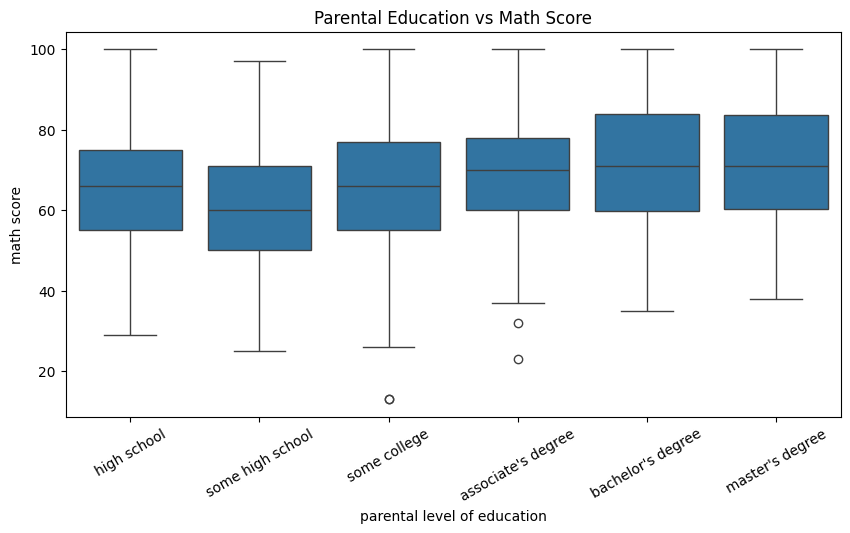

In [119]:
plt.figure(figsize=(10,5))

sns.boxplot(
    data=df,
    x='parental level of education',
    y='math score'
)

plt.xticks(rotation=30)
plt.title('Parental Education vs Math Score')

plt.show()

نمودار جعبه‌ای نشان می‌دهد دانش‌آموزانی که والدین با تحصیلات بالاتر دارند، به طور میانگین نمرات ریاضی بالاتری کسب کرده‌اند. بنابراین بین سطح تحصیلات والدین و عملکرد ریاضی یک رابطه مثبت مشاهده می‌شود

### کدام درس سخت‌تر بوده است؟

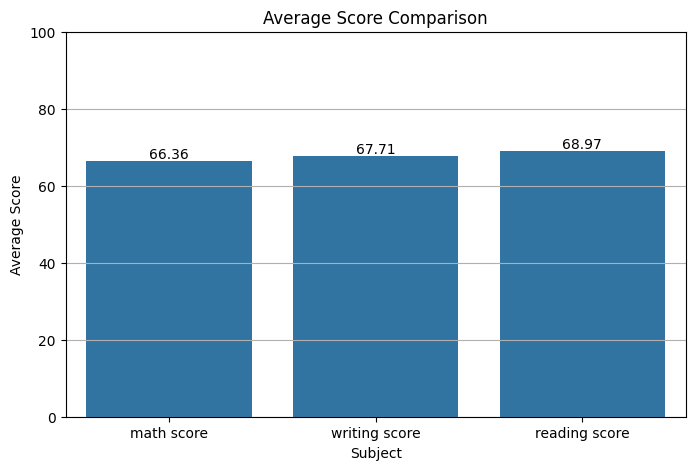

In [120]:
mean_scores = df[['math score', 'reading score', 'writing score']].mean()

mean_df = mean_scores.reset_index()
mean_df.columns = ['Subject', 'Average Score']

mean_df = mean_df.sort_values('Average Score')

plt.figure(figsize=(8,5))

ax = sns.barplot(
    data=mean_df,
    x='Subject',
    y='Average Score'
)

for c in ax.containers:
    ax.bar_label(c, fmt='%.2f')

plt.title('Average Score Comparison')
plt.ylim(0,100)
plt.grid(axis='y')

plt.show()

درس ریاضی سخ ترین درس و درس خواندن اسان ترین 

### دخترها در کدام درس بهتر هستند و پسرها در کدام؟

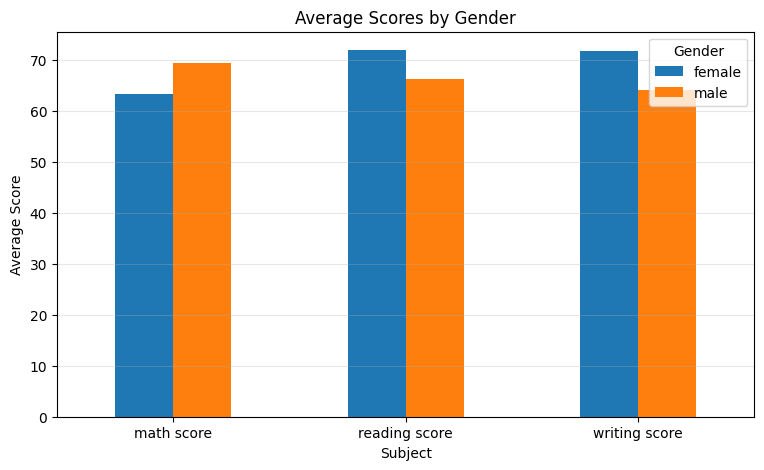

In [137]:
gender_scores = df.groupby('gender')[[
    'math score',
    'reading score',
    'writing score'
]].mean()

gender_scores.T.plot(
    kind='bar',
    figsize=(9,5)
)

plt.title('Average Scores by Gender')
plt.xlabel('Subject')
plt.ylabel('Average Score')

plt.xticks(rotation=0)
plt.legend(title='Gender')

plt.grid(axis='y', alpha=0.3)

plt.show()

دختر ها در خواندن بهترن  
پسر ها در ریاضی

### تحلیل همبستگی پیرسون

In [46]:
correlation = df[numerical_cols].corr()

correlation

,math score,reading score,writing score
math score,1.000000,0.819398,0.805944
reading score,0.819398,1.000000,0.954274
writing score,0.805944,0.954274,1.000000


### ایا همبستگی بین نمرات ریاضی و خواندن و نوشتن وجود دارد ؟

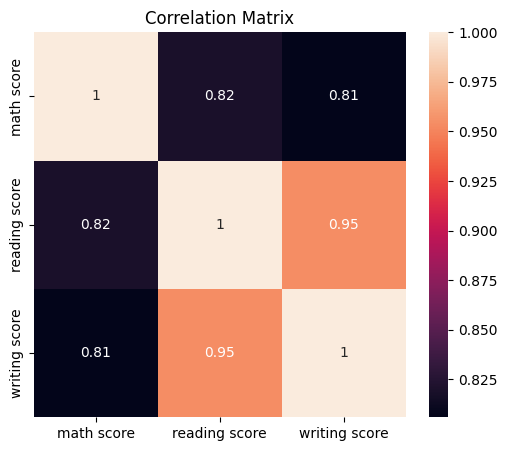

In [123]:
plt.figure(figsize=(6,5))

sns.heatmap(correlation, annot=True)

plt.title("Correlation Matrix")

plt.show()

قوی‌ترین ارتباط بین خواندن و نوشتن است
مهارت‌های خواندن و نوشتن احتمالاً به هم وابسته‌ تر هستند
نمره‌های سه درس به هم مرتبط‌اند یعنی دانش‌آموزی که در یک درس قوی باشد، احتمالاً در درس‌های دیگر هم عملکرد خوبی دارد

### همبستگی پیرسون بین نمرات ریاضی و خواندن

In [132]:
corr, p = pearsonr(
    df['math score'],
    df['reading score']
)

print(corr)
print(p)

0.8185658245191755
2.7264928441702713e-242


بین نمرات ریاضی و خواندن همبستگی مثبت و قوی وجود دارد


### آیا میانگین نمره ریاضی بین دختران و پسران تفاوت معناداری دارد یا خیر؟
### آزمون T-Test

In [128]:
female = df[df['gender']=='female']['math score']
male = df[df['gender']=='male']['math score']

t_stat, p_value = ttest_ind(female, male)

print(t_stat)
print(p_value)

-6.422469349638906
2.0720811781712897e-10


آزمون T نشان داد که تفاوت میانگین نمره ریاضی بین دو گروه دختر و پسر از نظر آماری معنادار است. با این حال، جنسیت تنها یکی از عوامل مؤثر بر عملکرد تحصیلی است و نمی‌توان آن را تنها دلیل تفاوت نمرات دانست.

###     نتیجه نهایی
<div style="direction: rtl; text-align: right;">
در این پروژه، عملکرد تحصیلی 1000 دانش‌آموز بر اساس عوامل مختلف بررسی شد. ابتدا داده‌ها از نظر کیفیت بررسی شدند و مشخص شد که دیتاست فاقد مقدار گمشده و داده تکراری است. همچنین داده‌های پرت شناسایی شدند، اما به دلیل واقعی بودن نمرات حذف نشدند.
نتایج تحلیل نشان داد که میانگین نمرات دانش‌آموزان در سه درس ریاضی، خواندن و نوشتن تفاوت‌هایی دارد و درس ریاضی به طور میانگین سخت‌تر از سایر دروس بوده است. همچنین مشاهده شد که دانش‌آموزانی که دوره آمادگی آزمون را گذرانده‌اند، در هر سه درس عملکرد بهتری داشته‌اند و آزمون آماری T-Test نیز وجود تفاوت معنادار در نمرات ریاضی این دو گروه را تأیید کرد.
بررسی تفاوت جنسیتی نشان داد که پسران در ریاضی و دختران در خواندن و نوشتن عملکرد بهتری داشته‌اند. علاوه بر این، بین سطح تحصیلات والدین و نمرات دانش‌آموزان رابطه مثبت مشاهده شد.
تحلیل همبستگی نشان داد که بین نمرات دروس مختلف ارتباط مثبت وجود دارد، به‌خصوص بین مهارت‌های خواندن و نوشتن که بیشترین همبستگی مشاهده شد. به طور کلی، نتایج نشان می‌دهد که عوامل فردی، خانوادگی و آموزشی می‌توانند با عملکرد تحصیلی دانش‌آموزان مرتبط باشند.
</div>